In [34]:
import pandas as pd
from datetime import datetime
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from sklearn.tree import DecisionTreeRegressor
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_squared_error, r2_score
import xgboost as xgb
from sklearn.ensemble import GradientBoostingRegressor,  ExtraTreesRegressor, RandomForestRegressor
from xgboost import XGBRegressor
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score
from scipy.stats import randint, uniform
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import VotingRegressor
import shap

In [35]:
# Caricare il DataFrame dal file CSV
video_data = pd.read_csv('data/video_data.csv')
# Rimuovi spazi e punti nei nomi delle colonne e sostituisci con underscore
video_data.columns = video_data.columns.str.replace(' ', '_').str.replace('.', '_')

# Verifica i nuovi nomi delle colonne
print(video_data.columns)

# Rimuovi uno degli underscore consecutivi nei nomi delle colonne
video_data.columns = video_data.columns.str.replace('N__di_like', 'N_di_like').str.replace('N__di_visualizzazioni', 'N_di_visualizzazioni').str.replace('N__di_commenti', 'N_di_commenti')

# Verifica i nuovi nomi delle colonne
print(video_data.columns)

# Modifica il formato data 
video_data['Data_di_pubblicazione'] = pd.to_datetime(video_data['Data_di_pubblicazione'], format="%Y-%m-%dT%H:%M:%SZ")

# Calcola l'età del video
video_data['Eta_del_video'] = (datetime.now() - video_data['Data_di_pubblicazione']).dt.days.astype(int)

# Calcola il rapporto tra like e visualizzazioni
video_data['Rapporto_Like_Visualizzazioni'] = video_data['N_di_like'] / video_data['N_di_visualizzazioni']

# Calcola il rapporto commenti/visualizzazioni
video_data['Rapporto_commenti_Visualizzazioni'] = video_data['N_di_commenti'] / video_data['N_di_visualizzazioni']


Index(['Titolo', 'Data_di_pubblicazione', 'N__di_like',
       'N__di_visualizzazioni', 'Durata', 'N__di_commenti'],
      dtype='object')
Index(['Titolo', 'Data_di_pubblicazione', 'N_di_like', 'N_di_visualizzazioni',
       'Durata', 'N_di_commenti'],
      dtype='object')


In [36]:
def convert_duration(duration_str):
    total_seconds = 0
    
    # Assicuriamoci che duration_str sia una stringa
    if isinstance(duration_str, str):
        # Rimuovi il prefisso 'PT' dalla stringa di durata
        duration_str = duration_str[2:]

        # Suddividi la stringa in parti utilizzando 'H', 'M' e 'S' come separatori
        parts = duration_str.split('H')
        
        # Se ci sono ore nella stringa, convertile in secondi
        if len(parts) > 1:
            total_seconds += int(parts[0]) * 3600 # 1 ora = 3600 secondi
            duration_str = parts[1]

        # Suddividi la stringa rimanente utilizzando 'M' come separatore per i minuti
        parts = duration_str.split('M')
        
        # Se ci sono minuti nella stringa, convertili in secondi
        if len(parts) > 1:
            total_seconds += int(parts[0]) * 60 # 1 minuto = 60 secondi
            duration_str = parts[1]

        # Rimuovi l'ultimo carattere 'S' dalla stringa dei secondi e convertili in secondi
        if duration_str[:-1].isnumeric():
            total_seconds += int(duration_str[:-1])

    return total_seconds


# Applica la funzione alla colonna 'Durata' del DataFrame
video_data['Durata'] = video_data['Durata'].apply(convert_duration)

In [37]:
# Salva il DataFrame in un file CSV
video_data.to_csv('data/video_prova.csv', index=False)

In [38]:
video_data = video_data[(video_data['Durata'] >= 100) & (video_data['Durata'] <= 4000)]


In [39]:
# Conta il numero totale di duplicati nel dataset
numero_duplicati = video_data.duplicated().sum()

# Stampare il numero di duplicati nel dataset
print(f"Il dataset contiene {numero_duplicati} righe duplicate.")

Il dataset contiene 76 righe duplicate.


In [40]:
video_data = video_data.drop_duplicates()
len(video_data)

378

In [41]:
summary_stats = video_data.describe()

print(summary_stats)

               Data_di_pubblicazione     N_di_like  N_di_visualizzazioni  \
count                            378  3.780000e+02          3.780000e+02   
mean   2021-02-12 08:26:57.415344128  4.714458e+04          1.036010e+06   
min              2014-12-22 11:00:08  6.220000e+03          7.542500e+04   
25%       2020-09-30 05:30:04.500000  1.509625e+04          1.732562e+05   
50%              2021-05-08 23:30:01  2.127500e+04          2.752450e+05   
75%       2021-10-28 00:00:20.500000  3.771300e+04          5.352648e+05   
max              2023-06-16 11:03:44  1.207120e+06          3.117214e+07   
std                              NaN  9.562064e+04          2.870984e+06   

            Durata  N_di_commenti  Eta_del_video  \
count   378.000000     378.000000     378.000000   
mean    661.730159    1338.259259    1088.129630   
min     121.000000       0.000000     234.000000   
25%     484.250000     324.250000     830.500000   
50%     532.000000     501.500000    1002.500000   
75%

In [42]:

# Ordina il DataFrame in base alla colonna 'Data_di_pubblicazione'
video_data_sorted = video_data.sort_values(by='Data_di_pubblicazione')

# Creazione del grafico per i like
fig_like = go.Figure()
fig_like.add_trace(go.Scatter(x=video_data_sorted['Data_di_pubblicazione'], y=video_data_sorted['N_di_like'],
                    mode='lines',
                    name='Like'))
fig_like.update_layout(title='Tendenze temporali dei Like',
                        xaxis_title='Data di pubblicazione',
                        yaxis_title='Like')

# Creazione del grafico per le visualizzazioni
fig_visualizzazioni = go.Figure()
fig_visualizzazioni.add_trace(go.Scatter(x=video_data_sorted['Data_di_pubblicazione'], y=video_data_sorted['N_di_visualizzazioni'],
                    mode='lines',
                    name='Visualizzazioni'))
fig_visualizzazioni.update_layout(title='Tendenze temporali delle Visualizzazioni',
                                  xaxis_title='Data di pubblicazione',
                                  yaxis_title='Visualizzazioni')

# Creazione del grafico per i commenti
fig_commenti = go.Figure()
fig_commenti.add_trace(go.Scatter(x=video_data_sorted['Data_di_pubblicazione'], y=video_data_sorted['N_di_commenti'],
                    mode='lines',
                    name='Commenti'))
fig_commenti.update_layout(title='Tendenze temporali dei Commenti',
                           xaxis_title='Data di pubblicazione',
                           yaxis_title='Commenti')

# Mostra i grafici
fig_like.show()
fig_visualizzazioni.show()
fig_commenti.show()




In [43]:
# Creazione del grafico
fig = px.scatter(video_data, 
                 x='Eta_del_video', 
                 y='Rapporto_Like_Visualizzazioni', 
                 size='N_di_visualizzazioni',
                 color='Durata',
                 opacity=0.6,
                 title="Influenza delle variabili sul Rapporto Like/Visualizzazioni",
                 labels={'Eta_del_video': 'Età del video', 'Rapporto_Like_Visualizzazioni': 'Rapporto Like/Visualizzazioni'},
                 hover_data={'Titolo': True, 'N_di_commenti': True})

# Personalizzazione del layout
fig.update_layout(xaxis_title="Età del video",
                  yaxis_title="Rapporto Like/Visualizzazioni")

# Mostra il grafico
fig.show()

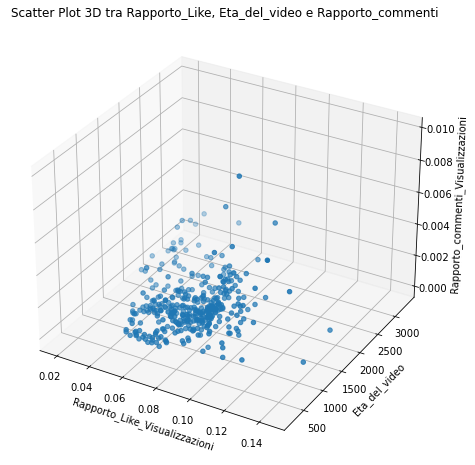

In [44]:

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(video_data['Rapporto_Like_Visualizzazioni'], video_data['Eta_del_video'], video_data['Rapporto_commenti_Visualizzazioni'])
ax.set_xlabel('Rapporto_Like_Visualizzazioni')
ax.set_ylabel('Eta_del_video')
ax.set_zlabel('Rapporto_commenti_Visualizzazioni')
ax.set_title('Scatter Plot 3D tra Rapporto_Like, Eta_del_video e Rapporto_commenti')
plt.show()

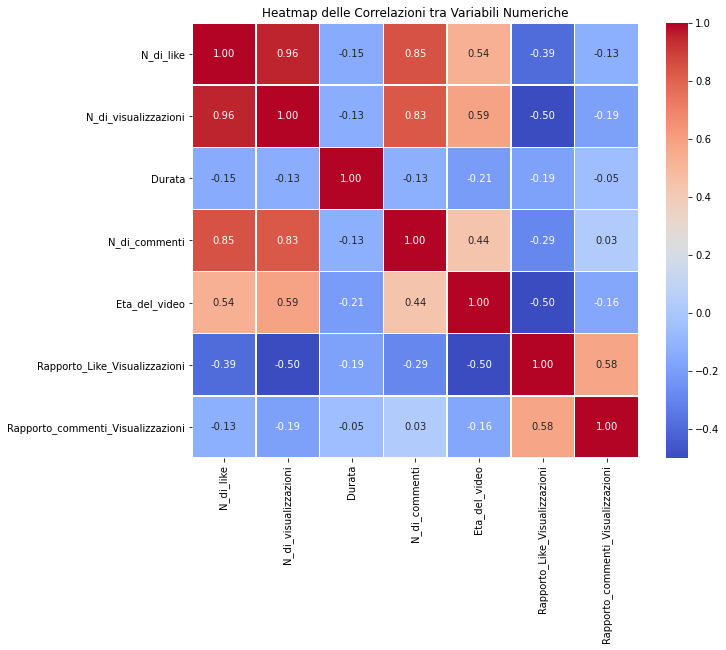

In [45]:
numerical_data = video_data.select_dtypes(include='number')

# Calcola la matrice di correlazione
correlation_matrix = numerical_data.corr()

# Crea l'heatmap utilizzando Seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Heatmap delle Correlazioni tra Variabili Numeriche')
plt.show()

In [46]:

# Ordina il DataFrame per la data di pubblicazione
video_data_sorted = video_data.sort_values(by='Data_di_pubblicazione')

# Creazione del grafico temporale interattivo con Plotly
fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_trace(go.Scatter(x=video_data_sorted['Data_di_pubblicazione'], y=video_data_sorted['Rapporto_Like_Visualizzazioni'], 
                         mode='lines', name='Rapporto Like/Visualizzazioni'), secondary_y=False)

# Aggiunta di bottoni per il controllo dell'intervallo di visualizzazione
fig.update_layout(title_text='Rapporto Like/Visualizzazioni nel tempo', xaxis_title='Data di pubblicazione', yaxis_title='Rapporto Like/Visualizzazioni')

# Aggiunta di slider per il controllo del range di visualizzazione
fig.update_layout(
    xaxis=dict(
        rangeselector=dict(
            buttons=list([
                dict(count=1, label="1m", step="month", stepmode="backward"),
                dict(count=6, label="6m", step="month", stepmode="backward"),
                dict(count=1, label="YTD", step="year", stepmode="todate"),
                dict(count=1, label="1y", step="year", stepmode="backward"),
                dict(step="all")
            ])
        ),
        rangeslider=dict(visible=True),
        type="date"
    )
)

# Mostra il grafico
fig.show()




In [47]:

# Inizializza lo scaler
scaler = MinMaxScaler()

# Seleziona le feature da normalizzare
features_to_normalize = ['Eta_del_video', 'N_di_visualizzazioni','Durata', 'Rapporto_commenti_Visualizzazioni']

# Applica la normalizzazione solo alle feature selezionate
video_data[features_to_normalize] = scaler.fit_transform(video_data[features_to_normalize])

In [48]:
features = ['Eta_del_video', 'Durata','N_di_visualizzazioni' ,'Rapporto_commenti_Visualizzazioni']
X = video_data[features]
y = video_data['Rapporto_Like_Visualizzazioni']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [49]:

# Modello di random forest
forest_model = RandomForestRegressor(random_state=42 )
forest_model.fit(X_train, y_train)
y_train_pred_forest = forest_model.predict(X_train)
y_test_pred_forest = forest_model.predict(X_test)

mse_train_forest = mean_squared_error(y_train, y_train_pred_forest)
r2_train_forest = r2_score(y_train, y_train_pred_forest)
mse_test_forest = mean_squared_error(y_test, y_test_pred_forest)
r2_test_forest = r2_score(y_test, y_test_pred_forest)

# Modello XGBoost
xgb_model = xgb.XGBRegressor(random_state=42 )
xgb_model.fit(X_train, y_train)
y_train_pred_xgb = xgb_model.predict(X_train)
y_test_pred_xgb = xgb_model.predict(X_test)

mse_train_xgb = mean_squared_error(y_train, y_train_pred_xgb)
r2_train_xgb = r2_score(y_train, y_train_pred_xgb)
mse_test_xgb = mean_squared_error(y_test, y_test_pred_xgb)
r2_test_xgb = r2_score(y_test, y_test_pred_xgb)

# Gradient boosting model
gradient_boosting_model = GradientBoostingRegressor(random_state=42)
gradient_boosting_model.fit(X_train, y_train)
y_train_pred_gb = gradient_boosting_model.predict(X_train)
y_test_pred_gb = gradient_boosting_model.predict(X_test)

mse_train_gb = mean_squared_error(y_train, y_train_pred_gb)
r2_train_gb = r2_score(y_train, y_train_pred_gb)
mse_test_gb = mean_squared_error(y_test, y_test_pred_gb)
r2_test_gb = r2_score(y_test, y_test_pred_gb)


# Extra trees model
extra_trees_model = ExtraTreesRegressor(random_state=42)
extra_trees_model.fit(X_train, y_train)
y_train_pred_extra_trees = extra_trees_model.predict(X_train)
y_test_pred_extra_trees = extra_trees_model.predict(X_test)

mse_train_extra_trees = mean_squared_error(y_train, y_train_pred_extra_trees)
r2_train_extra_trees = r2_score(y_train, y_train_pred_extra_trees)
mse_test_extra_trees = mean_squared_error(y_test, y_test_pred_extra_trees)
r2_test_extra_trees = r2_score(y_test, y_test_pred_extra_trees)

# Creazione del dizionario dei risultati
results_dict = {
    'Modello': ['Random Forest', 'XGBoost', 'Gradient Boosting', 'Extra Trees'],
    'MSE (Training)': [mse_train_forest,mse_train_xgb,mse_train_gb, mse_train_extra_trees],
    'R2 (Training)': [r2_train_forest,r2_train_xgb,r2_train_gb,r2_train_extra_trees],
    'MSE (Test)': [mse_test_forest, mse_test_xgb, mse_test_gb, mse_test_extra_trees],
    'R2 (Test)': [r2_test_forest, r2_test_xgb, r2_test_gb, r2_test_extra_trees]
}

# Creazione del DataFrame pandas
results_df = pd.DataFrame(results_dict)

# Visualizzazione del DataFrame
print(results_df)

             Modello  MSE (Training)  R2 (Training)  MSE (Test)  R2 (Test)
0      Random Forest    2.249973e-05       0.949364    0.000105   0.811877
1            XGBoost    1.757407e-06       0.996045    0.000134   0.758885
2  Gradient Boosting    3.467576e-05       0.921962    0.000094   0.830405
3        Extra Trees    1.201586e-32       1.000000    0.000120   0.783946


In [50]:

# Nomi dei modelli
modelli = ['Random Forest', 'XGBoost', 'Gradient Boosting',  'Extra Trees']

# Metriche di addestramento
mse_train = [mse_train_forest, mse_train_xgb, mse_train_gb,  mse_train_extra_trees]
r2_train = [r2_train_forest, r2_train_xgb, r2_train_gb,  r2_train_extra_trees]

# Metriche di test
mse_test = [mse_test_forest, mse_test_xgb, mse_test_gb, mse_test_extra_trees]
r2_test = [r2_test_forest, r2_test_xgb, r2_test_gb, r2_test_extra_trees]

# Creazione delle tracce per il grafico
trace_mse_train = go.Bar(x=modelli, y=mse_train, name='MSE - Addestramento', marker=dict(color='rgb(55, 83, 109)'))
trace_r2_train = go.Bar(x=modelli, y=r2_train, name='R^2 - Addestramento', marker=dict(color='rgb(26, 118, 255)'))
trace_mse_test = go.Bar(x=modelli, y=mse_test, name='MSE - Test', marker=dict(color='rgb(255, 153, 51)'))
trace_r2_test = go.Bar(x=modelli, y=r2_test, name='R^2 - Test', marker=dict(color='rgb(255, 51, 51)'))

# Creazione del layout del grafico
layout = go.Layout(title='Metriche dei Modelli',
                   xaxis=dict(title='Modelli'),
                   yaxis=dict(title='Metriche'),
                   barmode='group')

# Creazione della figura
fig = go.Figure(data=[trace_mse_train, trace_r2_train, trace_mse_test, trace_r2_test], layout=layout)

# Mostra il grafico
fig.show()


In [51]:

# Definizione dei modelli e dei relativi parametri da esplorare RANDOM SEARCH

modelli_parametri = {
    'Random Forest': (RandomForestRegressor(random_state=42), {
        'n_estimators': randint(50, 200),
        'max_depth': randint(5, 25),
        'min_samples_split': randint(2, 10),
        'min_samples_leaf': randint(1, 10)
    }),
    'XGBoost': (XGBRegressor(random_state=42), {
        'n_estimators': randint(100, 300),
        'max_depth': randint(3, 10),
        'learning_rate': uniform(0.01, 0.1),
        #'colsample_bytree': uniform(0.6, 1.0),
        'gamma': uniform(0, 0.5)
    }),
    'Gradient Boosting': (GradientBoostingRegressor(random_state=42), {
        'n_estimators': randint(200, 250),
        'learning_rate': uniform(0.01, 0.1),
        'max_depth': randint(3, 10)

    }),
    'Extra Trees': (ExtraTreesRegressor(random_state=42), {
        'n_estimators': randint(50, 200),
        'max_depth': randint(5, 15),
        'min_samples_split': randint(2, 10),
        'min_samples_leaf': randint(1,10)
    })
}

# Esecuzione della Random Search per tutti i modelli e successiva cross-validation
for nome_modello, (modello, parametri) in modelli_parametri.items():
    print(f"Esecuzione della Random Search per {nome_modello}")
    random_search = RandomizedSearchCV(estimator=modello, param_distributions=parametri, n_iter=100, 
                                       scoring='neg_mean_squared_error', cv=5, random_state=42)
    random_search.fit(X_train, y_train)
    
    # Utilizza i migliori parametri trovati per configurare il modello
    modello_migliorer = random_search.best_estimator_
    
    # Fai previsioni sul set di addestramento e test
    y_train_pred = modello_migliorer.predict(X_train)
    y_test_pred = modello_migliorer.predict(X_test)

    # Calcola le metriche di valutazione
    mse_train = mean_squared_error(y_train, y_train_pred)
    r2_train = r2_score(y_train, y_train_pred)
    mse_test = mean_squared_error(y_test, y_test_pred)
    r2_test = r2_score(y_test, y_test_pred)

    # Output delle metriche
    print(f"Migliori parametri trovati: {random_search.best_params_}")
    print(f"Modello: {nome_modello}")
    print(f"MSE (train): {mse_train}, R^2 (train): {r2_train}")
    print(f"MSE (test): {mse_test}, R^2 (test): {r2_test}")
    print()

   

Esecuzione della Random Search per Random Forest
Migliori parametri trovati: {'max_depth': 15, 'min_samples_leaf': 3, 'min_samples_split': 2, 'n_estimators': 185}
Modello: Random Forest
MSE (train): 6.206687279157873e-05, R^2 (train): 0.8603188787005619
MSE (test): 0.00011066145719038565, R^2 (test): 0.8009449177330181

Esecuzione della Random Search per XGBoost
Migliori parametri trovati: {'gamma': 0.00038938292050716417, 'learning_rate': 0.10922115592912175, 'max_depth': 3, 'n_estimators': 157}
Modello: XGBoost
MSE (train): 9.351001508921207e-05, R^2 (train): 0.7895562774001927
MSE (test): 0.00011325501358955941, R^2 (test): 0.7962796928615129

Esecuzione della Random Search per Gradient Boosting
Migliori parametri trovati: {'learning_rate': 0.01070663052197174, 'max_depth': 3, 'n_estimators': 248}
Modello: Gradient Boosting
MSE (train): 8.883121239279942e-05, R^2 (train): 0.8000858945305473
MSE (test): 0.00012021545141676295, R^2 (test): 0.7837594300754867

Esecuzione della Random S

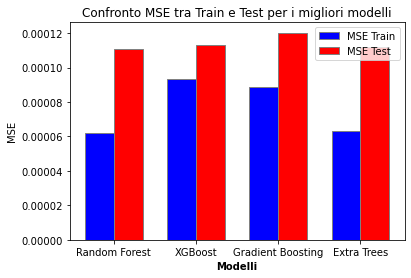

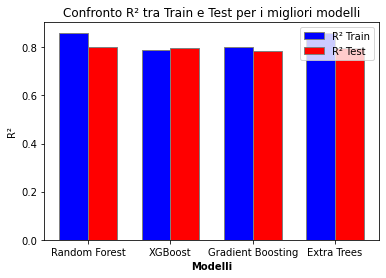

In [52]:

# Dati relativi al MSE e al R² dei migliori modelli
modelli = ['Random Forest', 'XGBoost', 'Gradient Boosting', 'Extra Trees']
mse_train = [6.207e-05, 9.351e-05, 8.883e-05,  6.312e-05]
r2_train = [0.8603, 0.7896, 0.8001, 0.8580]
mse_test = [0.0001106, 0.0001133, 0.0001202,  0.0001119]
r2_test = [0.8010, 0.7963, 0.7838,  0.7987]

# larghezza delle barre
bar_width = 0.35

# Posizione delle barre sul grafico
r1 = range(len(modelli))
r2 = [x + bar_width for x in r1]

# Creazione del grafico a barre per MSE
plt.bar(r1, mse_train, color='b', width=bar_width, edgecolor='grey', label='MSE Train')
plt.bar(r2, mse_test, color='r', width=bar_width, edgecolor='grey', label='MSE Test')

# Aggiunta delle etichette, del titolo e della legenda
plt.xlabel('Modelli', fontweight='bold')
plt.xticks([r + bar_width/2 for r in range(len(modelli))], modelli)
plt.ylabel('MSE')
plt.title('Confronto MSE tra Train e Test per i migliori modelli')
plt.legend()

# Mostra il grafico
plt.show()

# Creazione del grafico a barre per R²
plt.bar(r1, r2_train, color='b', width=bar_width, edgecolor='grey', label='R² Train')
plt.bar(r2, r2_test, color='r', width=bar_width, edgecolor='grey', label='R² Test')

# Aggiunta delle etichette, del titolo e della legenda
plt.xlabel('Modelli', fontweight='bold')
plt.xticks([r + bar_width/2 for r in range(len(modelli))], modelli)
plt.ylabel('R²')
plt.title('Confronto R² tra Train e Test per i migliori modelli')
plt.legend()

# Mostra il grafico
plt.show()



In [53]:

# Definizione dei parametri per ciascun modello GRID SEARCH
parametri_grid = {
    'Random Forest': {
        'n_estimators': [100,150,200],
        'max_depth': [15, 16,17],
        'min_samples_split': [2,3,4],
        'min_samples_leaf': [3,4, 5]
    },
    'XGBoost': {
        'n_estimators': [100, 200,300],
        'max_depth': [3, 5,8],
        'learning_rate': [0.02,0.1, 0.2],
        'colsample_bytree': [0.6,0.4],
        'gamma': [0.05 ,0, 0.1,]
    },
    'Gradient Boosting': {
        'n_estimators': [150, 200,220],
        'learning_rate': [0.01, 0.02],
        'max_depth': [3,4,5],
        'min_samples_split': [2, 3],
        'min_samples_leaf': [1, 2]
    },
    'Extra Trees': {
        'n_estimators': [50,100],
        'max_depth': [6,8,10],
        'min_samples_split': [2,4],
        'min_samples_leaf': [2,3,4]
    }
}
migliori_parametri = {}
# Loop sui modelli e esecuzione della Grid Search
for nome_modello, parametri in parametri_grid.items():
    # Crea il modello corrispondente
    if nome_modello == 'Random Forest':
        modello = RandomForestRegressor(random_state=42)
    elif nome_modello == 'XGBoost':
        modello = XGBRegressor(random_state=42)
    elif nome_modello == 'Gradient Boosting':
        modello = GradientBoostingRegressor(random_state=42)
    elif nome_modello == 'Bagging':
        modello = BaggingRegressor(random_state=42)
    elif nome_modello == 'Extra Trees':
        modello = ExtraTreesRegressor(random_state=42)
    else:
        raise ValueError("Modello non riconosciuto.")

    # Esegui la Grid Search
    grid_search = GridSearchCV(estimator=modello, param_grid=parametri, cv=5)
    grid_search.fit(X_train, y_train)

    migliori_parametri[nome_modello] = grid_search.best_params_

    # Utilizza i migliori parametri trovati per configurare il modello
    modello_migliore = grid_search.best_estimator_
    # Fai previsioni sul set di addestramento e test
    y_train_pred = modello_migliore.predict(X_train)
    y_test_pred = modello_migliore.predict(X_test)

    # Calcola le metriche di valutazione
    mse_train = mean_squared_error(y_train, y_train_pred)
    r2_train = r2_score(y_train, y_train_pred)
    mse_test = mean_squared_error(y_test, y_test_pred)
    r2_test = r2_score(y_test, y_test_pred)

    # Output delle metriche
    print(f"Migliori parametri trovati: {grid_search.best_params_}")
    print(f"Modello: {nome_modello}")
    print(f"MSE (train): {mse_train}, R^2 (train): {r2_train}")
    print(f"MSE (test): {mse_test}, R^2 (test): {r2_test}")
    print()


Migliori parametri trovati: {'max_depth': 17, 'min_samples_leaf': 3, 'min_samples_split': 2, 'n_estimators': 200}
Modello: Random Forest
MSE (train): 6.186557560431865e-05, R^2 (train): 0.8607718968013018
MSE (test): 0.00011183618306580685, R^2 (test): 0.7988318499882945

Migliori parametri trovati: {'colsample_bytree': 0.6, 'gamma': 0, 'learning_rate': 0.02, 'max_depth': 3, 'n_estimators': 300}
Modello: XGBoost
MSE (train): 6.395849185100522e-05, R^2 (train): 0.856061801464218
MSE (test): 9.57992921443225e-05, R^2 (test): 0.8276786112973442

Migliori parametri trovati: {'learning_rate': 0.02, 'max_depth': 3, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
Modello: Gradient Boosting
MSE (train): 7.543340774562491e-05, R^2 (train): 0.8302375727430523
MSE (test): 0.00010856326211393688, R^2 (test): 0.8047190989534599

Migliori parametri trovati: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
Modello: Extra Trees
MSE (train): 6.65

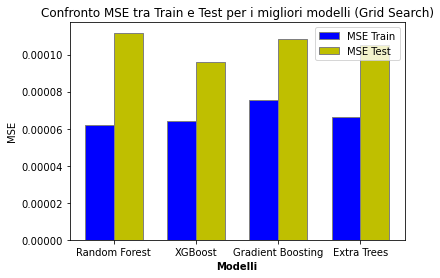

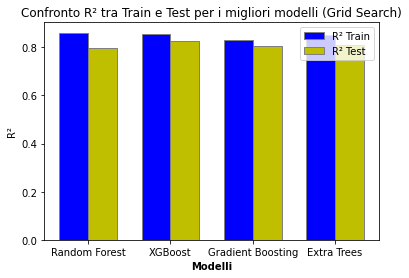

In [54]:

# Dati relativi ai modelli e alle prestazioni
modelli = ['Random Forest', 'XGBoost', 'Gradient Boosting', 'Extra Trees']
mse_train = [6.187e-05, 6.396e-05, 7.543e-05, 6.651e-05]
r2_train = [0.8608, 0.8561, 0.8302, 0.8503]
mse_test = [0.0001118, 9.579e-05, 0.0001085, 0.0001053]
r2_test = [0.7989, 0.8277, 0.8047, 0.8106]

# larghezza delle barre
bar_width = 0.35

# Posizione delle barre sul grafico
r1 = range(len(modelli))
r2 = [x + bar_width for x in r1]

# Creazione del grafico a barre per MSE
plt.bar(r1, mse_train, color='b', width=bar_width, edgecolor='grey', label='MSE Train')
plt.bar(r2, mse_test, color='y', width=bar_width, edgecolor='grey', label='MSE Test')

# Aggiunta delle etichette, del titolo e della legenda
plt.xlabel('Modelli', fontweight='bold')
plt.xticks([r + bar_width/2 for r in range(len(modelli))], modelli)
plt.ylabel('MSE')
plt.title('Confronto MSE tra Train e Test per i migliori modelli (Grid Search)')
plt.legend()

# Mostra il grafico
plt.show()

# Creazione del grafico a barre per R²
plt.bar(r1, r2_train, color='b', width=bar_width, edgecolor='grey', label='R² Train')
plt.bar(r2, r2_test, color='y', width=bar_width, edgecolor='grey', label='R² Test')

# Aggiunta delle etichette, del titolo e della legenda
plt.xlabel('Modelli', fontweight='bold')
plt.xticks([r + bar_width/2 for r in range(len(modelli))], modelli)
plt.ylabel('R²')
plt.title('Confronto R² tra Train e Test per i migliori modelli (Grid Search)')
plt.legend()

# Mostra il grafico
plt.show()


In [55]:

# Definizione dei migliori modelli e dei relativi parametri
migliori_parametri = {
    'Random Forest': {'max_depth': 15, 'min_samples_leaf': 3, 'min_samples_split': 2, 'n_estimators': 200},
    'XGBoost': {'colsample_bytree': 0.6, 'gamma': 0, 'learning_rate': 0.02, 'max_depth': 5, 'n_estimators': 300},
    'Gradient Boosting': {'learning_rate': 0.02, 'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 3, 'n_estimators': 200},
    'Extra Trees': {'max_depth': 10, 'min_samples_leaf': 3, 'min_samples_split': 4, 'n_estimators': 150}
}

# Creare le istanze dei migliori modelli con i relativi parametri
migliori_modelli = {
    'Random Forest': RandomForestRegressor(**migliori_parametri['Random Forest']),
    'XGBoost': XGBRegressor(**migliori_parametri['XGBoost']),
    'Gradient Boosting': GradientBoostingRegressor(**migliori_parametri['Gradient Boosting']),
    'Extra Trees': ExtraTreesRegressor(**migliori_parametri['Extra Trees'])
}

# Creare un ensemble model con i migliori modelli
ensemble_model = VotingRegressor([(nome_modello, modello) for nome_modello, modello in migliori_modelli.items()])

# Addestrare l'ensemble model sui dati di addestramento
ensemble_model.fit(X_train, y_train)

ensemble_model_score = ensemble_model.score(X_train, y_train)
print("Ensemble Model Score:", ensemble_model_score)

ensemble_model_score_test = ensemble_model.score(X_test, y_test)
print("Ensemble Model Score sul set di test:", ensemble_model_score_test)

# Predizioni sul set di test
y_test_pred = ensemble_model.predict(X_test)
y_train_pred = ensemble_model.predict(X_train)

Ensemble Model Score: 0.8995203467930345
Ensemble Model Score sul set di test: 0.8080406198694265


In [56]:

# Inizializza un array vuoto per raccogliere l'importanza delle feature dai singoli modelli
importanza_feature_totale = np.zeros(len(X_train.columns))

# Accumula l'importanza delle feature da ciascun modello
for modello in ensemble_model.estimators_:
    importanza_feature_totale += modello.feature_importances_

# Normalizza l'importanza delle feature
importanza_feature_totale /= len(ensemble_model.estimators_)

# Esegui il resto del codice per la visualizzazione come sopra



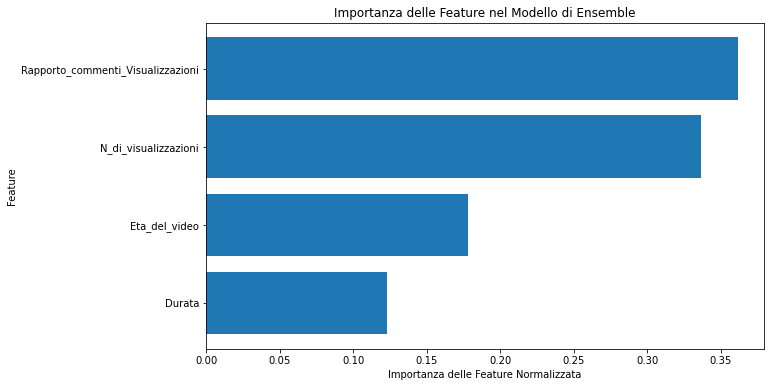

In [57]:

# Supponendo che importanza_feature_totale sia l'array contenente l'importanza normalizzata delle feature

# Estrai i nomi delle feature
nomi_feature = list(X_train.columns)

# Ordina le feature in base all'importanza
indice_feature_ordinati = importanza_feature_totale.argsort()
nomi_feature_ordinati = [nomi_feature[i] for i in indice_feature_ordinati]
importanza_feature_ordinati = importanza_feature_totale[indice_feature_ordinati]

# Creazione del grafico di importanza delle feature
plt.figure(figsize=(10, 6))
plt.barh(range(len(nomi_feature_ordinati)), importanza_feature_ordinati, align='center')
plt.yticks(range(len(nomi_feature_ordinati)), nomi_feature_ordinati)
plt.xlabel('Importanza delle Feature Normalizzata')
plt.ylabel('Feature')
plt.title('Importanza delle Feature nel Modello di Ensemble')
plt.show()


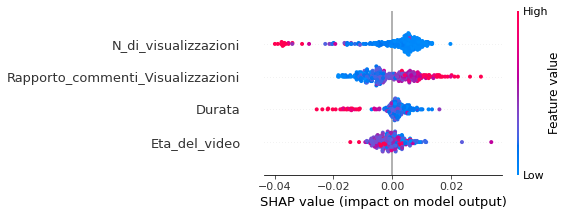

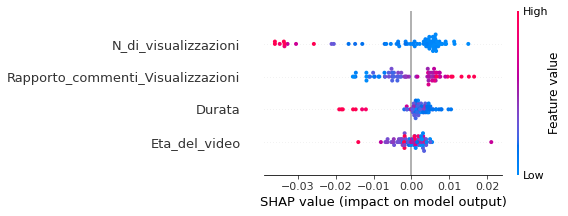

In [58]:

# Creare l'oggetto explainer SHAP utilizzando il modello di regressione gradient boosting
explainer_xgb = shap.Explainer(xgb_model, X_train)

# Calcolare i valori SHAP sia per il set di addestramento che per quello di test
shap_values_train_xgb = explainer_xgb.shap_values(X_train)
shap_values_test_xgb = explainer_xgb.shap_values(X_test)

# Creare i grafici di riepilogo SHAP per il set di addestramento e per quello di test
shap.summary_plot(shap_values_train_xgb, X_train)
shap.summary_plot(shap_values_test_xgb, X_test)


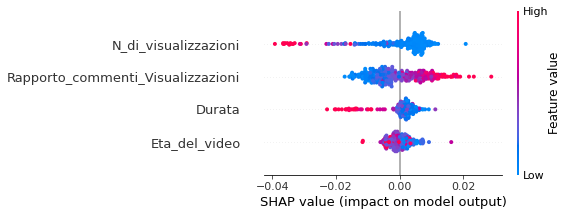

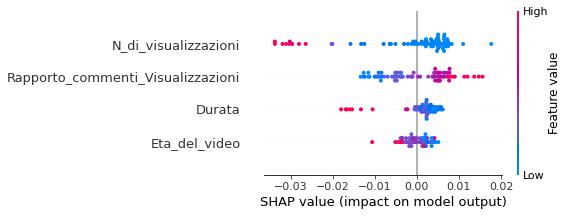

In [59]:

# Creare l'oggetto explainer SHAP utilizzando il modello di regressione gradient boosting
explainer_rf = shap.Explainer(forest_model, X_train)

# Calcolare i valori SHAP sia per il set di addestramento che per quello di test
shap_values_train_rf = explainer_rf.shap_values(X_train)
shap_values_test_rf = explainer_rf.shap_values(X_test)

# Creare i grafici di riepilogo SHAP per il set di addestramento e per quello di test
shap.summary_plot(shap_values_train_rf, X_train)
shap.summary_plot(shap_values_test_rf, X_test)

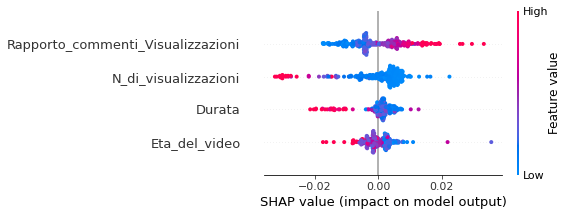

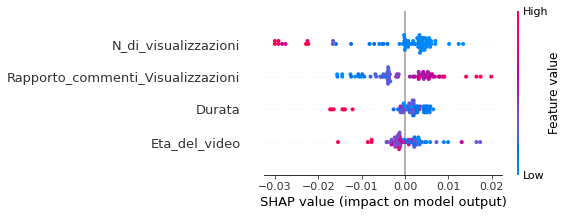

In [60]:

# Creare l'oggetto explainer SHAP utilizzando il modello di regressione gradient boosting
explainer_gb = shap.Explainer(gradient_boosting_model, X_train)

# Calcolare i valori SHAP sia per il set di addestramento che per quello di test
shap_values_train_gb = explainer_gb.shap_values(X_train)
shap_values_test_gb = explainer_gb.shap_values(X_test)

# Creare i grafici di riepilogo SHAP per il set di addestramento e per quello di test
shap.summary_plot(shap_values_train_gb, X_train)
shap.summary_plot(shap_values_test_gb, X_test)


 93%|=================== | 280/302 [00:11<00:00]       

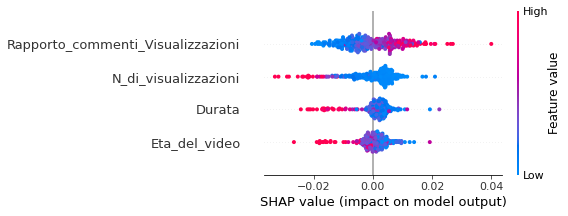

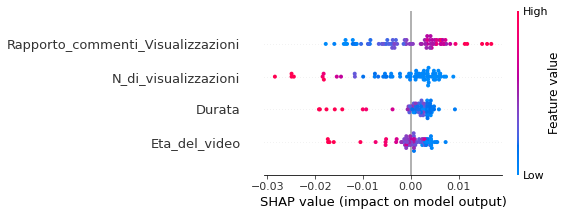

In [61]:
# Creare l'oggetto explainer SHAP utilizzando il modello di regressione gradient boosting
explainer_xt = shap.Explainer(extra_trees_model, X_train)

# Calcolare i valori SHAP sia per il set di addestramento che per quello di test
shap_values_train_xt = explainer_xt.shap_values(X_train)
shap_values_test_xt = explainer_xt.shap_values(X_test)

# Creare i grafici di riepilogo SHAP per il set di addestramento e per quello di test
shap.summary_plot(shap_values_train_xt, X_train)
shap.summary_plot(shap_values_test_xt, X_test)